# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [6]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv(r'C:\Users\Amulya MJ\data-viz-class-material-w2026\data\airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [7]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


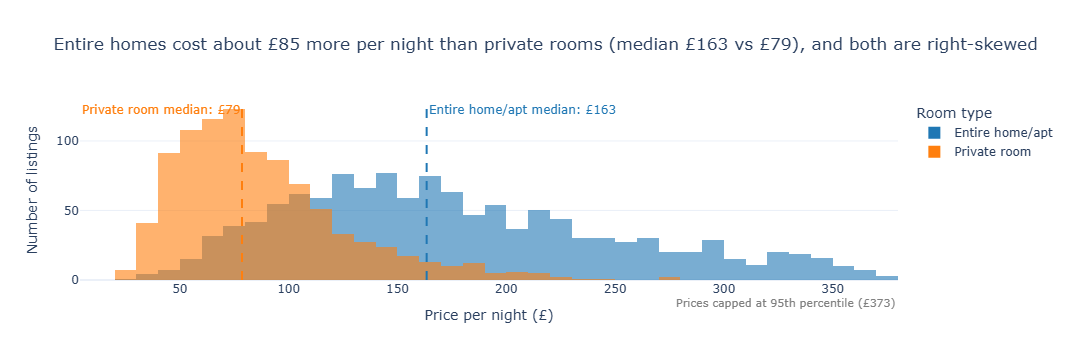

In [10]:
# Task 1

two_types = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])]

colors = {'Entire home/apt': '#1f77b4', 'Private room': '#ff7f0e'}
medians = two_types.groupby('room_type')['price'].median()

fig1 = px.histogram(
    two_types, x='price', color='room_type',
    barmode='overlay', opacity=0.6, nbins=40,
    color_discrete_map=colors,
    labels={'price': 'Price per night (£)', 'room_type': 'Room type'},
    title=(f"Entire homes cost about £{medians['Entire home/apt'] - medians['Private room']:.0f} more "
           f"per night than private rooms (median £{medians['Entire home/apt']:.0f} vs £{medians['Private room']:.0f}), "
           f"and both are right-skewed")
)


for room, med in medians.items():
    fig1.add_vline(
        x=med, line_dash='dash', line_width=2, line_color=colors[room],
        annotation_text=f"{room} median: £{med:.0f}",
        annotation_position='top right' if room == 'Entire home/apt' else 'top left',
        annotation_font_color=colors[room]
    )


fig1.add_annotation(
    text=f"Prices capped at 95th percentile (£{p95:.0f})",
    xref='paper', yref='paper', x=1, y=-0.18, showarrow=False,
    font=dict(size=11, color='grey')
)

fig1.update_layout(template='plotly_white', yaxis_title='Number of listings',
                   legend_title_text='Room type')
fig1.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

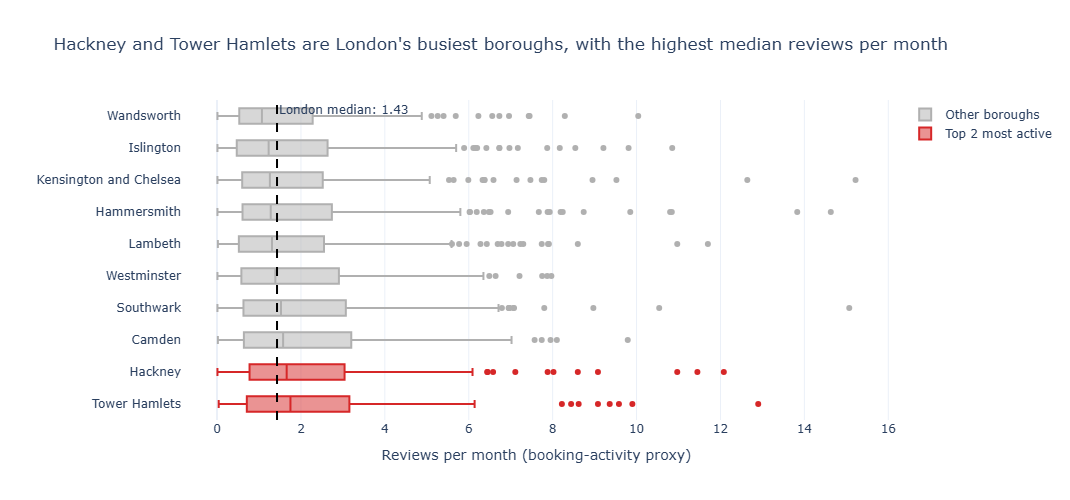

In [11]:
# Task 2

borough_col = 'neighbourhood'   # change if your column has a different name


active = df[df['reviews_per_month'] > 0].copy()


borough_medians = active.groupby(borough_col)['reviews_per_month'].median().sort_values()
order = borough_medians.index.tolist()

top2 = borough_medians.nlargest(2).index.tolist()
active['group'] = np.where(active[borough_col].isin(top2), 'Top 2 most active', 'Other boroughs')

overall_median = active['reviews_per_month'].median()

fig2 = px.box(
    active, x='reviews_per_month', y=borough_col,
    color='group', orientation='h',
    category_orders={borough_col: order},
    color_discrete_map={'Top 2 most active': '#d62728', 'Other boroughs': '#b0b0b0'},
    points='outliers',
    labels={'reviews_per_month': 'Reviews per month (booking-activity proxy)',
            borough_col: ''},
    title=f"{top2[1]} and {top2[0]} are London's busiest boroughs, "
          f"with the highest median reviews per month"
)


fig2.add_vline(
    x=overall_median, line_dash='dash', line_color='black',
    annotation_text=f"London median: {overall_median:.2f}",
    annotation_position='top right'
)

fig2.update_layout(
    template='plotly_white', legend_title_text='',
    height=max(500, 25 * len(order)),   # scale height with number of boroughs
    boxmode='overlay'                   # keeps boxes aligned despite the colour split
)
fig2.show()